In [ ]:
# Specify file to read in
fname = '/home/mattias/Desktop/tutorial/Altair_2026-09-29_22-27-59__-10.03_30.00s_0000.fits'


In [2]:
# Read in fits file using astropy
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

hdul = fits.open(fname)
hdul.info()

Filename: /home/mattias/Desktop/tutorial/Altair_2026-09-29_22-27-59__-10.03_30.00s_0000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      40   (1391, 350)   int16 (rescales to uint16)   


In [3]:
# Look at header information to see what file contains
hdr = hdul[0].header
hdr

SIMPLE  =                    T / C# FITS                                        
BITPIX  =                   16                                                  
NAXIS   =                    2 / Dimensionality                                 
NAXIS1  =                 1391                                                  
NAXIS2  =                  350                                                  
BZERO   =                32768                                                  
EXTEND  =                    T / Extensions are permitted                       
IMAGETYP= 'LIGHT'              / Type of exposure                               
EXPOSURE=                 30.0 / [s] Exposure duration                          
EXPTIME =                 30.0 / [s] Exposure duration                          
DATE-LOC= '2026-09-29T22:27:59.4167053' / Time of observation (local)           
DATE-OBS= '2026-09-30T02:27:59.4167053' / Time of observation (UTC)             
MJD-OBS =     61313.10277101

In [4]:
# Individual values can be read like a dictionary
print(hdr['OBJECT'], hdr['DATE-OBS'], hdr['EXPTIME'], 's', hdr['INSTRUME'], hdr['AIRMASS'])

Altair 2026-09-30T02:27:59.4167053 30.0 s Atik 414ex 1.36033037876905


In [ ]:
# Load in the image data 
data = hdul[0].data.astype(float)   # shape is (NAXIS2, NAXIS1) = (rows, cols)
hdul.close()

# Remember to subtract and normalize by dark/flat data. Not done here

print('shape :', data.shape)


shape : (350, 1391)


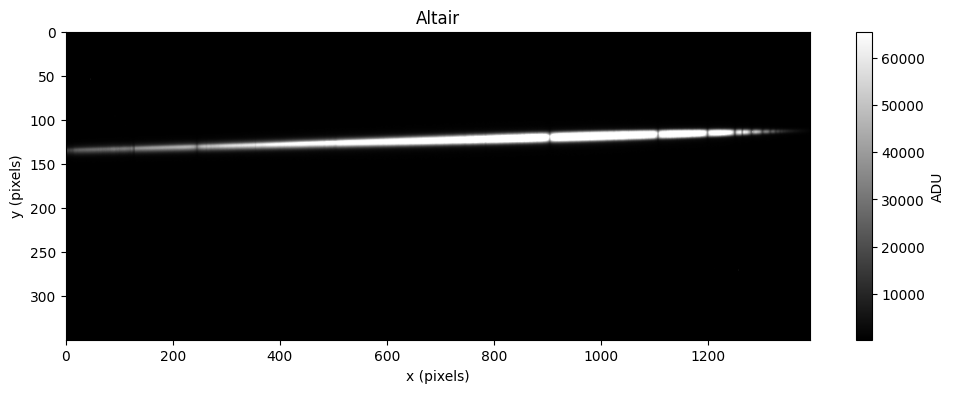

In [9]:
# Make an initial plot 
fig, ax = plt.subplots(figsize=(12, 4))
vmin, vmax = np.percentile(data, [1, 99.5])
im = ax.imshow(data, origin='upper', cmap='gray', vmin=vmin, vmax=vmax, aspect='auto')
ax.set_xlabel('x (pixels)')
ax.set_ylabel('y (pixels)')
ax.set_title(hdr['OBJECT'])
fig.colorbar(im, label='ADU')
plt.show()

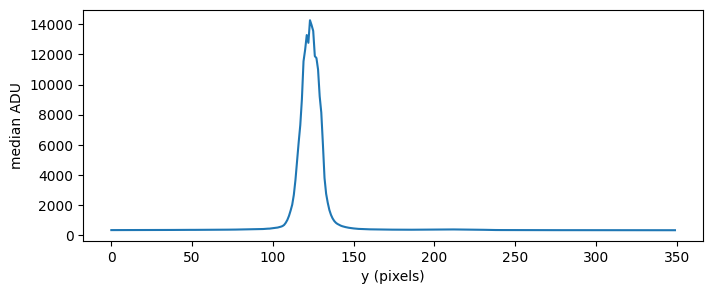

In [32]:
# Collapse x-axis to get aperture 
row_prof = np.median(data, axis=1)
y = np.arange(data.shape[0])


# By eye guess what aperture halfwidth is
aperture_halfwidth = 15 # pixels


fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(y, row_prof, label='data')

ax.set_xlabel('y (pixels)')
ax.set_ylabel('median ADU')
plt.show()

(100.0, 150.0)

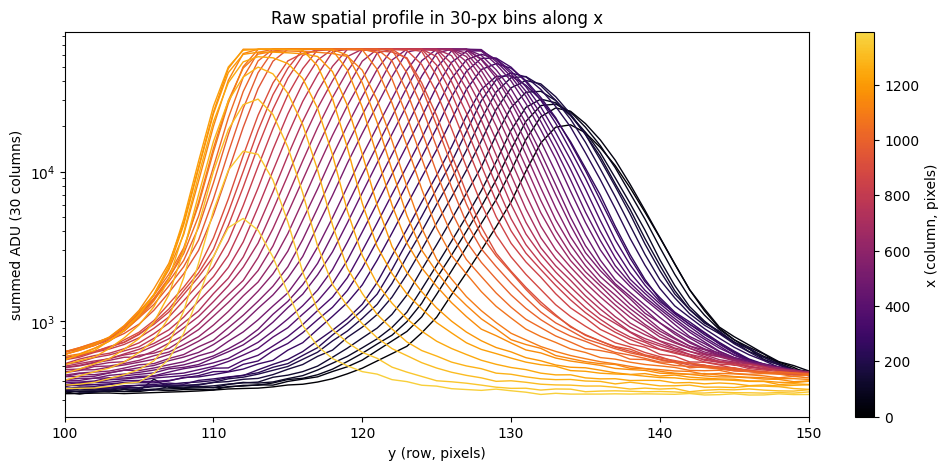

In [33]:
# Chunk original data rows into bins of 30 pixels, see if there's a drift 
from matplotlib.colors import ListedColormap

bin_width = 30 # how many pixels to average
nrows, ncols = data.shape
nbins = ncols // bin_width  

# 1) chunk: (rows, nbins, bin_width)
chunks = data[:, :nbins * bin_width].reshape(nrows, nbins, bin_width)

# 2) sum the pixels in each bin -> (rows, nbins)
binned_sum = chunks.sum(axis=2)/bin_width   # average ADU per column in each bin

# 3) Calculate bin centers 
x_centres = (np.arange(nbins) + 0.5) * bin_width


cmap = ListedColormap(plt.cm.inferno(np.linspace(0, 0.9, 256)))   # drop the near-white end
norm = plt.Normalize(0, ncols)
fig, ax = plt.subplots(figsize=(12, 5))
for i in range(nbins):
    ax.semilogy(y, binned_sum[:, i], color=cmap(norm(x_centres[i])), lw=1)

ax.set(xlabel='y (row, pixels)', ylabel=f'summed ADU ({bin_width} columns)',
       title=f'Raw spatial profile in {bin_width}-px bins along x')
fig.colorbar(plt.cm.ScalarMappable(cmap=cmap, norm=norm), ax=ax, label='x (column, pixels)');

ax.set_xlim(100,150)


In [34]:
from scipy.optimize import curve_fit

# Define function to fit to each of these peaks 
def gaussian(y, amp, mu, sigma, offset):
    return amp * np.exp(-0.5 * ((y - mu) / sigma)**2) + offset


# Fit a Gaussian to each binned profile
y_centres = np.full(nbins, np.nan)
y_errs = np.full(nbins, np.nan)
for i in range(nbins):
    prof = binned_sum[:, i]
    p0 = [prof.max() - np.median(prof), np.argmax(prof), 5, np.median(prof)] # Initial guess to give optimizer
    try:
        popt, pcov = curve_fit(gaussian, y, prof, p0=p0)
        y_centres[i], y_errs[i] = popt[1], np.sqrt(pcov[1, 1])
    except RuntimeError:                         
        pass

    

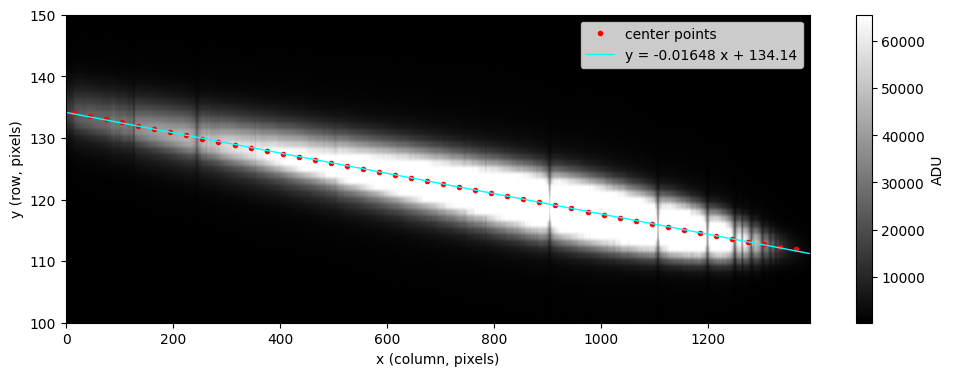

In [35]:
# Fit a line to the centers 
# good = np.isfinite(y_centres)
slope, intercept = np.polyfit(x_centres, y_centres, 1)
x_line = np.arange(ncols)


# Overplot the fitted centres on the image
fig, ax = plt.subplots(figsize=(12, 4))
vmin, vmax = np.percentile(data, [1, 99.5])
im = ax.imshow(data, origin='upper', cmap='gray', vmin=vmin, vmax=vmax, aspect='auto')
ax.plot(x_centres, y_centres, marker='o',ls='none', ms=3, color='red', label='center points')
ax.plot(x_line, slope * x_line + intercept, color='cyan', lw=1,
        label=f'y = {slope:.5f} x + {intercept:.2f}')
ax.set(xlabel='x (column, pixels)', ylabel='y (row, pixels)')
ax.legend(loc='upper right')
fig.colorbar(im, label='ADU')

ax.set_ylim(100,150)

plt.show()

[Text(0.5, 0, 'x (column, pixels)'),
 Text(0, 0.5, 'Altair summed ADU'),
 (0.0, 1390.0)]

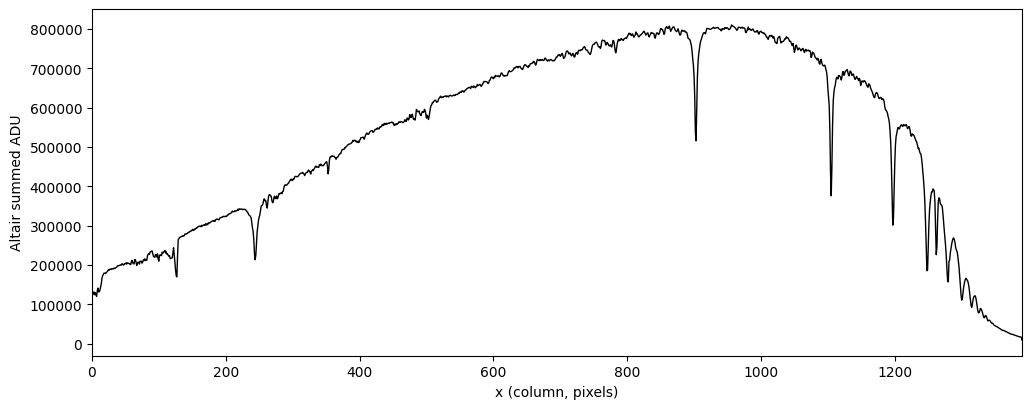

In [39]:
# Calculate trace 
x_cols = np.arange(ncols)
trace_y = slope * x_cols + intercept

# Extract signal inside of aperture 
in_aperture = np.abs(y[:, None] - trace_y[None, :]) <= aperture_halfwidth
ap_lo, ap_hi = trace_y - aperture_halfwidth, trace_y + aperture_halfwidth

# Collapse over y-column axis to get spectrum
spectrum = np.where(in_aperture, data, 0).sum(axis=0) # zero out data outside of aperture

# Plot spectrum
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(x_cols, spectrum, color='k', lw=1, label=f"{hdr['OBJECT']} ")
ax.set(xlabel='x (column, pixels)', ylabel=f"{hdr['OBJECT']} summed ADU", xlim=(0, ncols - 1))

